# Testing the MACE v2 class on the shipped weights

In this notebook, the reworked `MACE` class (`src/mace/mace.py`, version 2) is tested on the shipped trained model,
by recreating Fig. 12 of [Maes et al. (2024)](https://ui.adsabs.harvard.edu/abs/2024ApJ...969...79M/abstract):
a fully autoregressive evolution of the test model `data/test/mid_dens`.

The weights in `model/example_weights_v2/` are the shipped model `20240604_160152` (≈ int4 in the paper),
converted to the v2 `state_dict` format (only `encoder.*`, `decoder.*` and `g.*` are kept).

In [1]:
import matplotlib.pyplot    as plt
import numpy                as np
import torch
from time                   import time

from pathlib import Path
import sys

parentpath = str(Path().cwd())+'/'

print(parentpath)

sys.path.append(parentpath)

import src.mace.CSE_0D.dataset  as ds
import src.mace.CSE_0D.plotting as plotting
import src.mace.load            as load
import src.mace.utils           as utils

specs_dict = utils.get_specs()

%reload_ext autoreload
%autoreload 2

c:\Users\bartd\Documents\Astronomy\Thesis\MACE/


## Setting up
### Meta data of the shipped model
The meta data contains the architecture (`n_dim`, `p_dim`, `z_dim`, `ae_type`, `g_nn`), the hyperparameters of the training,
the normalisation of the time steps (`dt_fract`), and the ODE solver tolerances (`atol`, `rtol`).
The shipped model was trained with `atol = 1e-5` and `rtol = 1e-2`. The loader passes the tolerances from `meta.json`
to the `MACE` constructor, so the model is solved with the tolerances it was trained with.

The shipped model has no final `nn.pt`, only snapshots `nn/nn{k}.pt`. As in `load&test.ipynb`, snapshot 7 is used.

In [2]:
modelpath = parentpath + 'model/example_weights_v2/'
epoch     = 7

meta = utils.load_meta(modelpath)

print('n, p, z: ', meta['n_dim'], meta['p_dim'], meta['z_dim'], '| ae_type:', meta['ae_type'], '| g_nn:', meta['g_nn'])
print('nb_evol: ', meta['nb_evol'], '| losstype:', meta['losstype'])
print('dt_fract:', meta['dt_fract'])
print('atol:    ', meta['atol'], '| rtol:', meta['rtol'])

n, p, z:  468 4 8 | ae_type: simple | g_nn: False
nb_evol:  16 | losstype: abs_idn
dt_fract: 0.221
atol:     1e-05 | rtol: 0.01


### Loading the test data
The test model has $\dot M = 10^{-6}\,{\rm M_\odot\,yr^{-1}}$ and $v_{\rm exp} = 17.5$ km/s, which corresponds to `data/test/mid_dens`.

`get_test_data` returns the 1D model, the normalised input `(n, p, dt)` and some specifics of the model:
- `n`: (N, 468) abundances, log10, scaled to [0,1]
- `p`: (N-1, 4) physical parameters (density, temperature, $\xi$, $A_V$), log10, scaled to [0,1]
- `dt`: (N-1,) time steps, scaled with `dt_fract`

In [3]:
testpath = 'mid_dens'

model1D, (n, p, dt), info = ds.get_test_data('1DCSE', testpath, meta, inpackage=True)

print('\nn: ', tuple(n.shape))
print('p: ', tuple(p.shape))
print('dt:', tuple(dt.shape))
print(info)

> Train state: False
Found paths: 13
[12  5  0  3 11  3  7  9  3  5]
number of test paths: 3
Selected test paths: 3
Selected paths: 3


c:\Users\bartd\Documents\Astronomy\Thesis\MACE\
-------------------
Input of test model
-------------------
Mdot [Msol/yr]:       1e-06
v [km/s]:             17.5
Density proxi Mdot/v: 5.714285714285714e-13

Temp at 1e16 cm [K]:  93.91
Tstar:                2100.0
eps:                  0.5
-------------------


n:  (135, 468)
p:  (134, 4)
dt: (134,)
{'path': '', 'name': 'mid_dens', 'Tstar': 2100.0, 'Mdot': 1e-06, 'v': 1750000.0, 'eps': 0.5}


c:\Users\bartd\Documents\Astronomy\Thesis\MACE\src\mace\CSE_0D\dataset.py:262: UserWarning: Input line 14 contained no data and will not be counted towards `max_rows=50000`.  This differs from the behaviour in NumPy <=1.22 which counted lines rather than rows.  If desired, the previous behaviour can be achieved by using `itertools.islice`.
Please see the 1.23 release notes for an example on how to do this.  If you wish to ignore this warning, use `warnings.filterwarnings`.  This warning is expected to be removed in the future and is given only once per `loadtxt` call.
  paths = np.loadtxt(loc + 'data/paths_train_data.txt', dtype=str)


## Loading the model
`load.load_MACE(dir, epoch)` builds a `MACE` from the architecture and tolerances in `meta.json` (`utils.load_model`),
and loads the weights `nn/nn{epoch}.pt` with a strict `load_state_dict`, which fails if any key is missing or unexpected.
It also returns the training/validation losses it finds in `dir` (there are none for the converted weights).

The `MACE` constructor no longer takes training settings (`lr`, `scheme`, `nb_evol`, ...), and its `state_dict`
only holds the encoder, the decoder and the latent ODE `g`.

In [4]:
model, losses, _ = load.load_MACE(modelpath, epoch=epoch)

print(f'The model has {utils.count_parameters(model)} trainable parameters')
print('state_dict prefixes:', sorted({key.split('.')[0] for key in model.state_dict()}))

The model has 284692 trainable parameters
state_dict prefixes: ['decoder', 'encoder', 'g']


## Fig. 12: evolution of the test model
Starting from the abundances of the first step, `n[0]`, MACE predicts every next step from its *own* previous prediction,
using the true physical parameters `p[i]` and time step `dt[i]` of each step. In the v2 class this is a single call to
`MACE.rollout`, with a batch of B = 1 chain of k = N-1 steps:
- `n0`: (1, 468)
- `p_seq`: (1, N-1, 4)
- `dt`: (1, N-1)

The initial abundances are prepended to the prediction, so that it has the same N rows as the real model.

In [5]:
tic = time()
with torch.no_grad():
    n_hat, status = model.rollout(n[0:1], p[None], dt[None])
toc = time()

n_evol = torch.cat((n[0:1], n_hat[0]), dim=0)      ## (N, 468)

print(f'Evolution of {n_hat.shape[1]} steps in {toc-tic:.2f} s')
print('Solver status counts [success, general error, dt_min, max_steps, inf. norm]:',
      torch.bincount(status.flatten(), minlength=5).tolist())

Evolution of 134 steps in 0.41 s
Solver status counts [success, general error, dt_min, max_steps, inf. norm]: [134, 0, 0, 0, 0]


Denormalise the abundances, and compute the error between the real and predicted abundances (Eq. 23 of the paper):

$$ {\rm error} = \frac{\log_{10}\boldsymbol{n}-\log_{10}\hat{\boldsymbol{n}}}{\log_{10}\boldsymbol{n}}, $$

which is executed element-wise, summed over the species and averaged over the steps.

In [6]:
n_real = ds.get_abs(n.numpy())
n_evol = ds.get_abs(n_evol.numpy())

err, err_evol = utils.error(n_real, n_evol)

print('Evolution error (Eq. 23):', np.round(err_evol, 3))

Evolution error (Eq. 23): 15.711


### Plotting
- Upper panel: H$_2$ number density (dash-dotted, left axis) and temperature (grey, right axis).
- Middle panel: abundances; dashed = real, full = MACE evolution.
- Lower panel: error (Eq. 23) of MACE compared to the classical model.

The species are the same as in Fig. 12 of the paper.

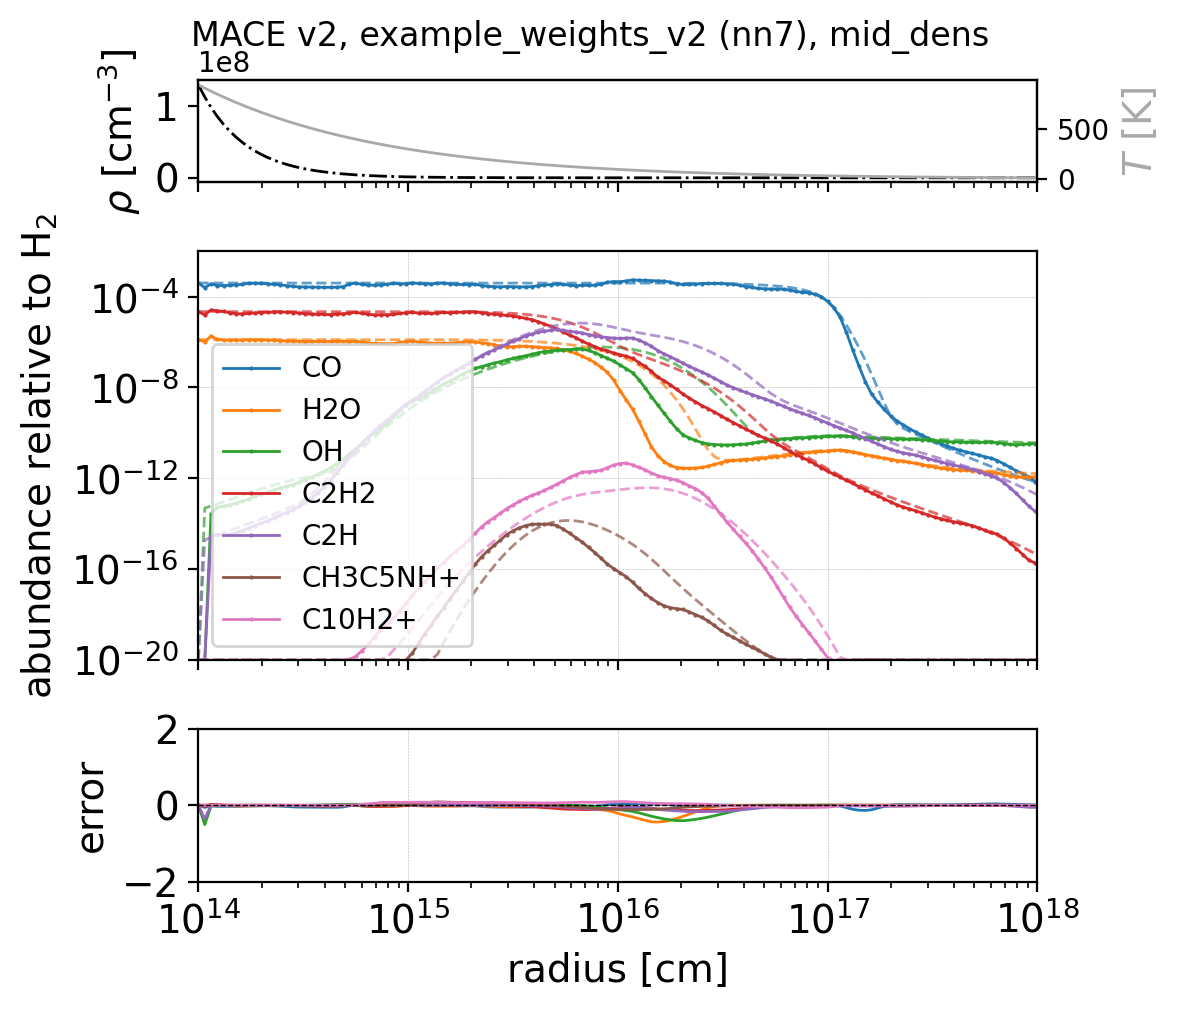

In [7]:
fig12_specs = ['CO', 'H2O', 'OH', 'C2H2', 'C2H', 'CH3C5NH+', 'C10H2+']

fig12, axes = plotting.plot_abs(model1D, '1DCSE', n_real, n_evol, specs=fig12_specs, step=False)
fig12.suptitle(f'MACE v2, example_weights_v2 (nn{epoch}), {testpath}', y=1.0)
plt.show()